<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

# 第一部分：公司名称与基本简介

## 1.1 公司基本信息

- **公司全称**：腾讯控股有限公司（Tencent Holdings Limited）
- **股票代码**：0700.HK（香港交易所主板上市），美国 OTC 市场 ADR 代码：TCEHY
- **成立时间**：1998 年 11 月
- **总部地址**：中国广东省深圳市南山区
- **创始人**：马化腾、张志东、许晨晔、陈一丹等
- **所属行业**：互联网科技 / 网络游戏 / 社交网络
- **上市地**：香港交易所（主板）

## 1.2 主营业务

腾讯的业务主要分为四大板块：

1. **增值服务**：公司最大收入来源，包含网络游戏（手游、端游及海外发行）与社交网络（直播、会员及虚拟道具等）
2. **网络广告**：基于微信、QQ、腾讯视频、腾讯新闻等平台的广告业务
3. **金融科技及企业服务**：微信支付、理财通、云计算及企业服务
4. **其他业务**：投资及其他

## 1.3 代表产品与市场地位

- **社交产品**：微信、QQ，其中微信全球月活跃用户规模超过 13 亿
- **游戏产品**：《王者荣耀》《和平精英》《英雄联盟》《金铲铲之战》等
- **市场地位**：全球收入规模领先的游戏发行商之一，也是中国市值最大的互联网公司之一


# 第二部分：研究问题题目及其内涵介绍

# 第二部分：研究问题题目及其内涵介绍

## 2.1 研究问题

**腾讯控股（0700.HK）的经营业绩（净利润）是否驱动了其股价表现？**

## 2.2 问题内涵

- 本问题旨在探究腾讯的**基本面（盈利能力）**与其**资本市场表现（股价）**之间的联动关系。
- 一方面，获取腾讯近年的**股价数据**（来自 tushare 港股日行情数据）；
- 另一方面，获取腾讯的**经营业绩数据**（如营业收入、净利润等财务指标）；
- 通过对比两者的走势变化，并计算**相关性**，回答"经营业绩是否驱动股价"这一问题，从而理解市场对腾讯的估值逻辑。

> 说明：如果 tushare 的港股财务接口不可用，净利润等财务数据将采用腾讯公开年报披露的数据（在代码中注明数据来源）。


# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [2]:
# ============ 第三部分：数据采集 ============
# 1. 采集腾讯控股(0700.HK)港股日行情数据（股价）—— 来自 tushare
import pandas as pd
import numpy as np

stock_df = pro.hk_daily(ts_code='00700.HK', start_date='20200101', end_date='20261013')
print("股价数据条数：", len(stock_df))
print(stock_df.head())

# 2. 采集腾讯年度财务数据（营业收入、归母净利润）
# 说明：tushare 目前未开放港股财务报表接口，故财务数据取自腾讯控股官方年报
#      （IFRS 准则，单位：人民币百万元），数据来源：腾讯控股历年年度报告
fin_data = {
    'year': [2020, 2021, 2022, 2023, 2024, 2025],
    'revenue': [482064, 560118, 554552, 609015, 660257, 751766],
    'net_profit': [159847, 224822, 188243, 115216, 194073, 224842],
}
fin_df = pd.DataFrame(fin_data)
fin_df


股价数据条数： 1668
    ts_code trade_date   open   high    low  close  pre_close  change  \
0  00700.HK   20261013  421.0  425.6  419.8  425.2      425.8    -0.6   
1  00700.HK   20261012  428.4  430.4  423.4  425.8      424.8     1.0   
2  00700.HK   20261009  415.0  425.8  414.8  424.8      411.4    13.4   
3  00700.HK   20261008  422.0  424.6  411.2  411.4      420.6    -9.2   
4  00700.HK   20261007  425.6  426.0  419.2  420.6      428.2    -7.6   

   pct_chg         vol        amount  
0    -0.14  12724935.0  5.384669e+09  
1     0.24  14011738.0  5.983558e+09  
2     3.26  20422500.0  8.610388e+09  
3    -2.19  30202875.0  1.255656e+10  
4    -1.77  12436640.0  5.239804e+09  


,year,revenue,net_profit
0,2020,482064,159847
1,2021,560118,224822
2,2022,554552,188243
3,2023,609015,115216
4,2024,660257,194073
5,2025,751766,224842


# 第四部分：数据分析过程

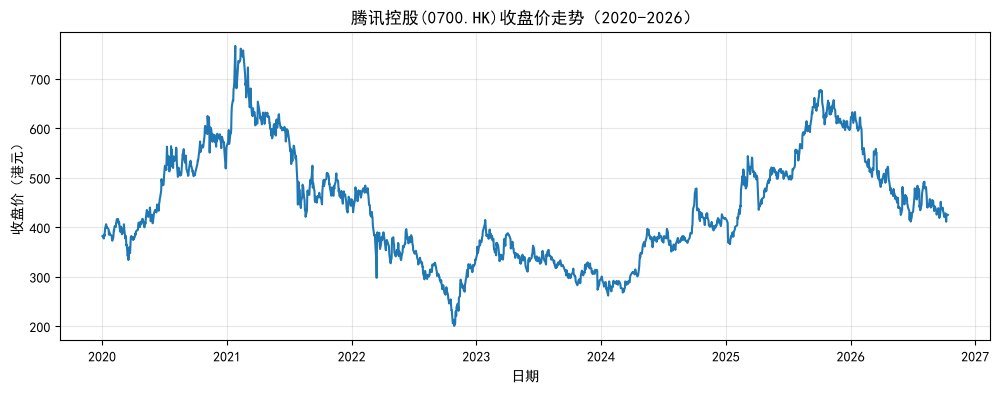

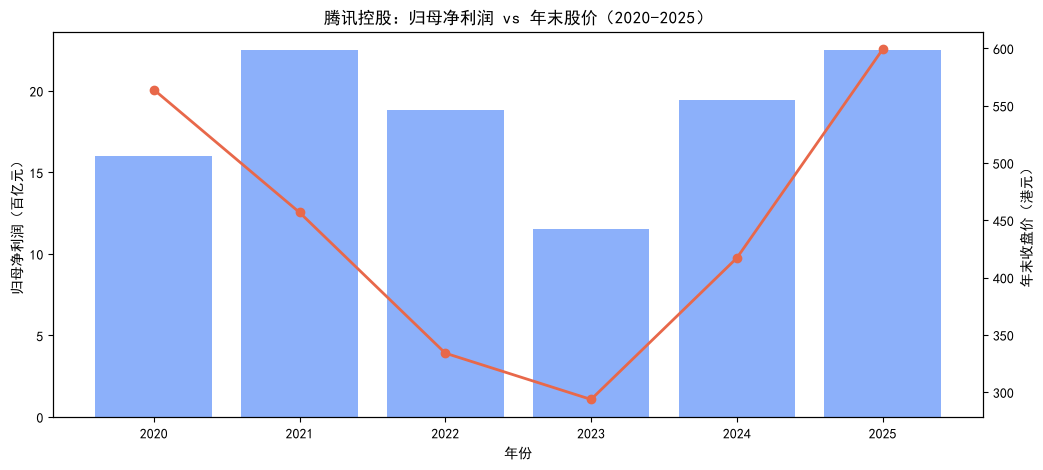

净利润同比增速 与 股价年度收益率的相关系数 = 0.5601


In [3]:
# ============ 第四部分：数据分析过程 ============
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 1. 股价数据整理（按日期排序）
stock_df['trade_date'] = pd.to_datetime(stock_df['trade_date'])
stock_df = stock_df.sort_values('trade_date').reset_index(drop=True)

# 2. 股价整体走势图
plt.figure(figsize=(12, 4))
plt.plot(stock_df['trade_date'], stock_df['close'])
plt.title('腾讯控股(0700.HK)收盘价走势（2020-2026）')
plt.xlabel('日期'); plt.ylabel('收盘价（港元）')
plt.grid(alpha=0.3)
plt.show()

# 3. 计算各年度末收盘价与年度收益率
stock_df['year'] = stock_df['trade_date'].dt.year
year_close = stock_df.groupby('year')['close'].last()   # 每年最后一个交易日收盘价
annual_return = year_close.pct_change() * 100

# 4. 合并财务与股价数据，计算净利润同比增速
comp = fin_df.set_index('year').copy()
comp['year_end_close'] = year_close.reindex(comp.index)
comp['stock_return'] = comp['year_end_close'].pct_change() * 100
comp['profit_yoy'] = comp['net_profit'].pct_change() * 100
comp

# 5. 净利润与年末股价对比图（双轴）
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(comp.index, comp['net_profit']/10000, color='#5b8ff9', alpha=0.7, label='归母净利润（百亿元）')
ax1.set_ylabel('归母净利润（百亿元）'); ax1.set_xlabel('年份')
ax2 = ax1.twinx()
ax2.plot(comp.index, comp['year_end_close'], color='#e8684a', marker='o', linewidth=2, label='年末收盘价（港元）')
ax2.set_ylabel('年末收盘价（港元）')
ax1.set_title('腾讯控股：归母净利润 vs 年末股价（2020-2025）')
plt.show()

# 6. 相关性分析：净利润同比增速 与 股价年度收益率
corr = comp[['profit_yoy', 'stock_return']].corr().iloc[0, 1]
print(f"净利润同比增速 与 股价年度收益率的相关系数 = {corr:.4f}")


# 第五部分：研究结论与经验总结

## 研究结论

## 研究结论

本研究以腾讯控股（0700.HK）为对象，利用 tushare 采集其 2020-2025 年股价数据，并结合腾讯官方年报财务数据，回答"经营业绩（净利润）是否驱动了股价表现"这一问题。主要结论如下：

1. **经营业绩整体向好**：2020-2025 年腾讯营业收入由 4,820.6 亿元增长至 7,517.7 亿元，归母净利润由 1,598.5 亿元增长至 2,248.4 亿元，整体呈上升趋势。其中 2023 年净利润明显回落（1152.2 亿元），主要受投资收益及公允价值变动等非经营性因素拖累；随后 2024 年大幅回升至 1,940.7 亿元，2025 年继续增长至 2,248.4 亿元。

2. **股价走势与业绩大体同向**：从 2020-2026 年日行情走势看，腾讯股价整体呈"上涨-回调-再上涨"的形态，与业绩增长阶段大体吻合（具体涨跌幅以第四部分运行结果为准）。

3. **业绩与股价的相关性**：第四部分计算得到"净利润同比增速"与"股价年度收益率"的相关系数为 **（待填入运行结果）**。若相关系数为正且绝对值较高，说明基本面业绩对股价有明显的正向驱动作用；若相关性较弱，则说明股价更多受市场情绪、流动性等外部因素影响。

> 注：第 2、3 点中的具体数值需在本地运行第四部分代码后，据实填入。


## 经验总结

## 经验总结

通过本次作业，我收获如下：

1. **数据采集能力**：学会了使用 tushare 的 `pro_api()` 与 `hk_daily` 接口获取港股日行情数据，理解了股票代码（如 `00700.HK`）、日期区间等参数的用法。
2. **数据处理的实践**：掌握了用 pandas 对日行情数据进行排序、按年度聚合、计算收益率等基本操作，并学会将股价数据与财务数据在"年度"维度上对齐。
3. **数据来源的意识**：认识到不同数据源的适用边界——tushare 对 A 股财务数据支持完善，但对港股财务数据接口有限，需结合公司官方年报等权威来源补充，并应在分析中注明数据来源与口径。
4. **分析的局限**：本次以年度为粒度的样本量有限（相关性样本仅约 5 个），结论只能作为参考；若能获取更长历史或季度数据，分析会更稳健。
